In [1]:
import pandas as pd
import numpy as np

import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score
from sklearn.metrics import classification_report, recall_score

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
refrence_dir = data_dir + '/CHCH_v6_reference/'
reference_mask_dir = refrence_dir + 'processed{}/'
output_dir = data_dir + '/CHCH_v6_model/figures/peaks/'

In [2]:
infile = refrence_dir + 'peaks_training_df.csv'
peaks_df = pd.read_csv(infile, index_col=[0]) 
print('  <--- ' + infile)

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v6_reference/peaks_training_df.csv


In [3]:
## Filtering

peaks_df = peaks_df.dropna() # removes NaNs (e.g. no temperature data, so bad classification)

# Exclude case study dates from training dataset                           
eval_dates = [20211117, 20210904, 20211028, 20210529, 20211110, 20211129, 20210605, 20210808, 20210519, 20210704, 20211110, 20210707, 20210618, 20211102, 20210514]                     
peaks_df = peaks_df[~peaks_df['date'].isin(eval_dates)]

peaks_df = peaks_df.reset_index(drop=True)

In [20]:
len(eval_dates)

15

In [151]:
peaks_df

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target
0,20210515,65,20,0.000027,1.373274,0.000014,0.000027,1.025,1,0,3.064716,1,0,0,0,0,0,0
1,20210515,67,20,0.000167,2.111095,0.000084,0.000166,1.025,1,0,3.010916,1,0,0,0,0,0,0
2,20210515,68,19,0.000308,1.774225,0.000155,0.000308,0.975,1,0,3.326631,1,0,0,0,0,0,0
3,20210515,69,20,0.000290,1.246414,0.000145,0.000289,1.025,1,0,2.961364,1,0,0,0,0,0,0
4,20210515,70,20,0.000113,1.418176,0.000057,0.000112,1.025,1,0,2.938228,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34537,20220120,284,63,0.000036,1.655835,0.000018,0.000036,3.175,1,0,-4.586685,0,0,0,0,0,1,0
34538,20220120,286,228,0.000026,3.522913,0.000013,0.000026,11.425,1,0,-54.901438,0,0,0,0,1,0,0
34539,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,0,1,1,0,0,0
34540,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,-0.414722,0,1,1,0,0,0,0


In [51]:
print('WLWC Occurrence:', peaks_df.wlwc_target.sum(), peaks_df.wlwc_target.mean())
print('SLWC Occurrence:', peaks_df.slwc_target.sum(), peaks_df.slwc_target.mean())
print('MPC Occurrence:', peaks_df.mpc_target.sum(), peaks_df.mpc_target.mean())
print('IC Occurrence:',peaks_df.ic_target.sum(), peaks_df.ic_target.mean())
print('Undet Occurrence:',peaks_df.undet_target.sum(), peaks_df.undet_target.mean())

WLWC Occurrence: 19288 0.5583926813734005
SLWC Occurrence: 8006 0.23177580915986334
MPC Occurrence: 799 0.0231312604944705
IC Occurrence: 5945 0.17210931619477737
Undet Occurrence: 518 0.014996236465751838


In [53]:
test_pks = peaks_df.query('ic_target == 1 & undet_target == 1')
test_pks

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target
3042,20210610,43,153,0.000042,2.017292,0.000021,0.000043,7.675,2,1,-40.486557,0,0,0,0,1,1,0
5760,20210625,38,164,0.000039,12.178113,0.000019,0.000040,8.225,1,0,-46.398761,0,0,0,0,1,1,1
5791,20210625,59,166,0.000025,20.244091,0.000013,0.000025,8.325,2,0,-47.102552,0,0,0,0,1,1,1
5792,20210625,59,169,0.000025,1.700298,0.000024,0.000002,8.475,2,1,-48.001165,0,0,0,0,1,1,1
7542,20210706,5,173,0.000033,2.642696,0.000016,0.000034,8.675,1,0,-48.169317,0,0,0,0,1,1,0
15058,20210905,259,219,0.000022,2.879075,0.000011,0.000022,10.975,1,0,-58.448665,0,0,0,0,1,1,0
16989,20211007,68,170,0.000022,8.161693,0.000011,0.000022,8.525,1,0,-47.161812,0,0,0,0,1,1,1
16990,20211007,69,159,0.000032,5.829680,0.000016,0.000033,7.975,1,0,-44.047145,0,0,0,0,1,1,1
18562,20211016,279,154,0.000023,1.358997,0.000021,0.000004,7.725,3,2,-42.663280,0,0,0,0,1,1,1
19783,20211024,78,203,0.000025,3.147253,0.000012,0.000025,10.175,2,1,-49.408056,0,0,0,0,1,1,0


In [84]:
# 1-(peaks_df.wlwc_target.mean()+peaks_df.slwc_target.mean()+peaks_df.mpc_target.mean()+peaks_df.ic_target.mean())
# 34542-(peaks_df.wlwc_target.sum()+peaks_df.slwc_target.sum()+peaks_df.mpc_target.sum()+peaks_df.ic_target.sum())
# 504/34542

23+56+2+17+1

99

In [54]:
import xarray as xr

In [72]:
reference_mask_dir = data_dir + '/CHCH_v6_reference/processed{}/'
infile = reference_mask_dir.format('20210610'[:6]) + '{}.nc'.format('20210610')
ds = xr.open_dataset(infile)

ic_target = ds.layer_ice.values
undet_target = ds.layer_undet.values

ic_target[43]
# undet_target[43]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], d

In [70]:
(43/288)*24

3.583333333333333

In [30]:
print('Number of days: ',len(peaks_df.date.unique()))

Number of days:  211


In [5]:
wlcw_peaks = peaks_df.query('wlwc_target == 1')
# no_wlwc_peaks = peaks_df.query('wlwc_target == 0')

slwc_peaks = peaks_df.query('slwc_target == 1')
# no_slwc_peaks = peaks_df.query('slwc_target == 0')

slcc_peaks = peaks_df.query('slcc_target == 1')
# no_slcc_peaks = peaks_df.query('slcc_target == 0')


liq_peaks = peaks_df.query('slwc_target == 1 | wlwc_target == 1')
non_liq_peaks = peaks_df.query('(slwc_target == 0 & wlwc_target == 0) & undet_target == 0')

mpc_peaks = peaks_df.query('mpc_target == 1')


ic_peaks = peaks_df.query('ic_target == 1')
# no_ic_peaks = peaks_df.query('ic_target == 0')

u_peaks = peaks_df.query('undet_target == 1')



In [32]:
slcc_peaks

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target
17,20210515,215,134,0.000035,1.742540,0.000018,0.000035,6.725,1,0,-37.182311,0,1,1,0,0,0,0
36,20210515,242,120,0.000083,2.822551,0.000042,0.000082,6.025,1,0,-32.604442,0,1,1,0,0,0,0
37,20210515,243,121,0.000053,3.420853,0.000027,0.000053,6.075,1,0,-33.081271,0,1,1,0,0,0,0
107,20210516,35,97,0.000188,2.621117,0.000095,0.000187,4.875,1,0,-21.542441,0,1,1,0,0,0,0
108,20210516,36,98,0.000265,2.026547,0.000133,0.000264,4.925,1,0,-21.948529,0,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34535,20220120,282,62,0.000220,1.962705,0.000110,0.000220,3.125,1,0,-4.408565,0,1,1,0,0,0,0
34536,20220120,283,62,0.000199,1.804206,0.000099,0.000199,3.125,1,0,-4.375582,0,1,1,0,0,0,0
34539,20220121,35,53,0.000070,1.861522,0.000035,0.000070,2.675,1,0,-0.646539,0,0,1,1,0,0,0
34540,20220121,36,52,0.000105,1.742200,0.000052,0.000105,2.625,1,0,-0.414722,0,1,1,0,0,0,0


In [6]:
c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1)
c2 = (0.8,0,0,1)    
c3 = (0,0,1)
c4 = (0.8,0.8,0)
c5 = (0.7,0.7,0.7)


### Figs 2, 3

/tmp/ipykernel_19829/4227403833.py:31: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(liq_peaks[var],label='Liquid',ax=ax, color=c2,bins=30)
/tmp/ipykernel_19829/4227403833.py:32: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(non_liq_peaks[var],label='Non-Liquid',ax=ax, color=c4,bins=30)
/tmp/ipy

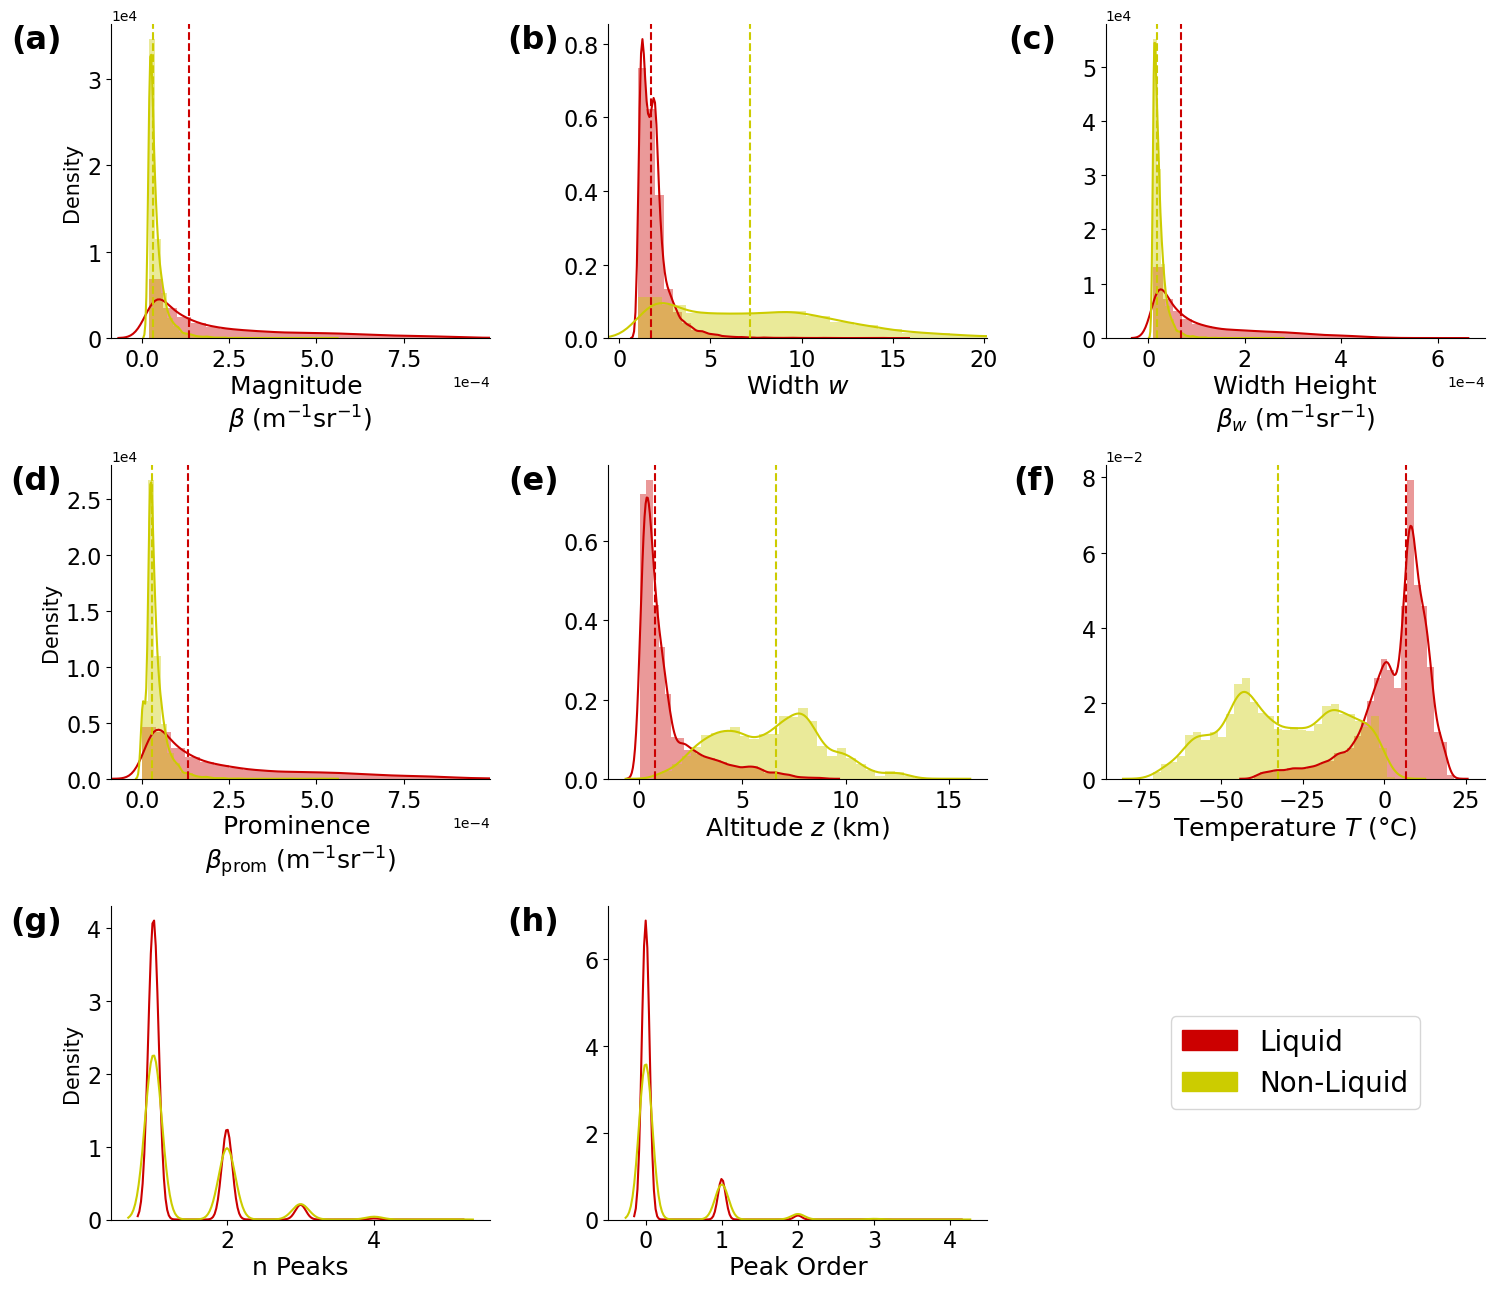

In [14]:
fig, axes = plt.subplots(3,3, figsize=(15,13))

var_list = ['peak_magnitude', 'peak_width', 'peak_width_height',
        'peak_prominence', 'peak_alt', 'peak_temp', 'num_peaks','peak_order',]

units_list = ['Magnitude \n$\\beta$ (m$^{-1}$sr$^{-1}$)', 'Width $w$', ' Width Height \n$\\beta_w$ (m$^{-1}$sr$^{-1}$)',
        'Prominence \n$\\beta_{\\text{prom}}$ (m$^{-1}$sr$^{-1}$)', 'Altitude $z$ (km)', 'Temperature $T$ ($\\degree$C)', 'n Peaks','Peak Order',]

letters='abcdefgh'

for i,var in enumerate(var_list):
    # print(var)
    
    ax = axes.flatten()[i]
    
    ax.tick_params(axis='both',which='major',labelsize=16)
    ax.tick_params(axis='both',which='minor',labelsize=16)
    
    ax.ticklabel_format(axis='x',style='sci',scilimits=(0,5))
    
    if var in ['num_peaks','peak_order']:
        sns.distplot(liq_peaks[var],label='Liquid',ax=ax, color=c2,bins=30,hist=False)
        sns.distplot(non_liq_peaks[var],label='Non-Liquid',ax=ax, color=c4,bins=30,hist=False)

        # sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30,hist=False)
        # sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30,hist=False)
        # sns.distplot(mpc_peaks[var],label='MPC',ax=ax, color=c1,bins=30,hist=False)
        # sns.distplot(ic_peaks[var],label='IC',ax=ax, color=c4,bins=30,hist=False)    
        # sns.distplot(u_peaks[var],label='Un',ax=ax, color=c5,bins=30,hist=False)    
    else:
        sns.distplot(liq_peaks[var],label='Liquid',ax=ax, color=c2,bins=30)
        sns.distplot(non_liq_peaks[var],label='Non-Liquid',ax=ax, color=c4,bins=30)

        # sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30)
        # sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30)
        # sns.distplot(mpc_peaks[var],label='MPC',ax=ax, color=c1,bins=30)
        # sns.distplot(ic_peaks[var],label='IC',ax=ax, color=c4,bins=30)    
        # sns.distplot(u_peaks[var],label='Un',ax=ax, color=c5,bins=30)    

        ax.axvline(np.nanmedian(liq_peaks[var]),c=c2,linestyle='--', label='Liquid Median')
        ax.axvline(np.nanmedian(non_liq_peaks[var]),c=c4,linestyle='--', label='Non-Liquid Median')

        # ax.axvline(np.nanmedian(wlcw_peaks[var]),c=c3,linestyle='--', label='WLWC Median')
        # ax.axvline(np.nanmedian(slwc_peaks[var]),c=c2,linestyle='--', label='SLWC Median')
        # ax.axvline(np.nanmedian(mpc_peaks[var]),c=c1,linestyle='--', label='MPC Median')
        # ax.axvline(np.nanmedian(ic_peaks[var]),c=c4,linestyle='--', label='IC Median')
        # ax.axvline(np.nanmedian(u_peaks[var]),c=c5,linestyle='--', label='Undetermined Median')
    
    unit = units_list[i]
    ax.set_xlabel(unit,fontsize=18,labelpad=2)
    # ax.set_title(var,fontsize=20)
    
    ax.ticklabel_format(axis='both',style='sci',scilimits=(-2,2))
    
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
        
    
    if i in [0,3,6]:
        ax.set_ylabel('Density', fontsize=15)
    else:
        ax.set_ylabel(' ')
            
    ax.text(-0.13,1,'({})'.format(letters[i]),fontsize=23,transform=ax.transAxes,ha='right',va='top',weight='semibold')
        

# print(axes[0,2].get_xlim())
axes[0,0].set_xlim(-8.789452652380182e-05, 0.0009970278532549434) #height
# axes[0,0].set_xlim(-8.789452652380182e-02, 0.9970278532549434) #height

axes[0,2].set_xlim(-8.789452652380182e-05, 0.0006970278532549434) #width height
axes[1,0].set_xlim(-8.789452652380182e-05, 0.0009970278532549434) #prom

axes[0,1].set_xlim(-0.6,20.2) # width
# axes[1,1].set_xlim(-1,9) # altitude

axes[2,2].axis('off')

colour_labels = ['Liquid','Non-Liquid']
patch_colors = [ c2,c4]
patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

# colour_labels = ['WLWC','SLWC','MPC', 'IC', 'Undetermined']
# patch_colors = [ c3,c2,c1, c4, c5]
# patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

# linestyle_labels = ['WLWC Median', 'SLWC Median','MPC Median','IC Median', 'Undetermined Median']
# patches_lines = [mlines.Line2D([],[],color=patch_colors[i],linestyle='dashed', label=linestyle_labels[i]) for i in range(5)] 
# patches = [patches_colours[0]] + [patches_lines[0]] + [patches_colours[1]] + [patches_lines[1]]  + [patches_colours[2]] + [patches_lines[2]] + [patches_colours[3]] + [patches_lines[3]] + [patches_colours[4]] + [patches_lines[4]]
patches = patches_colours
axes[2,2].legend(handles=patches, loc='center', fontsize=20)#,borderaxespad=0. )
    
# plt.text(0.2,0.65,'# Liquid peaks   =    '+ str(len(LCC_peaks)),transform=axes[2,2].transAxes,fontsize=17)
# plt.text(0.2,0.55,'# Ice peaks = '+ str(len(ICC_peaks)),transform=axes[2,2].transAxes,fontsize=17)
plt.tight_layout()

output_fpath = output_dir+'feature_dist_liq_noliq_med.png'
plt.savefig(output_fpath, dpi=150)
# plt.show()

/tmp/ipykernel_19829/2845343926.py:31: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30)
/tmp/ipykernel_19829/2845343926.py:32: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30)
/tmp/ipykernel_198

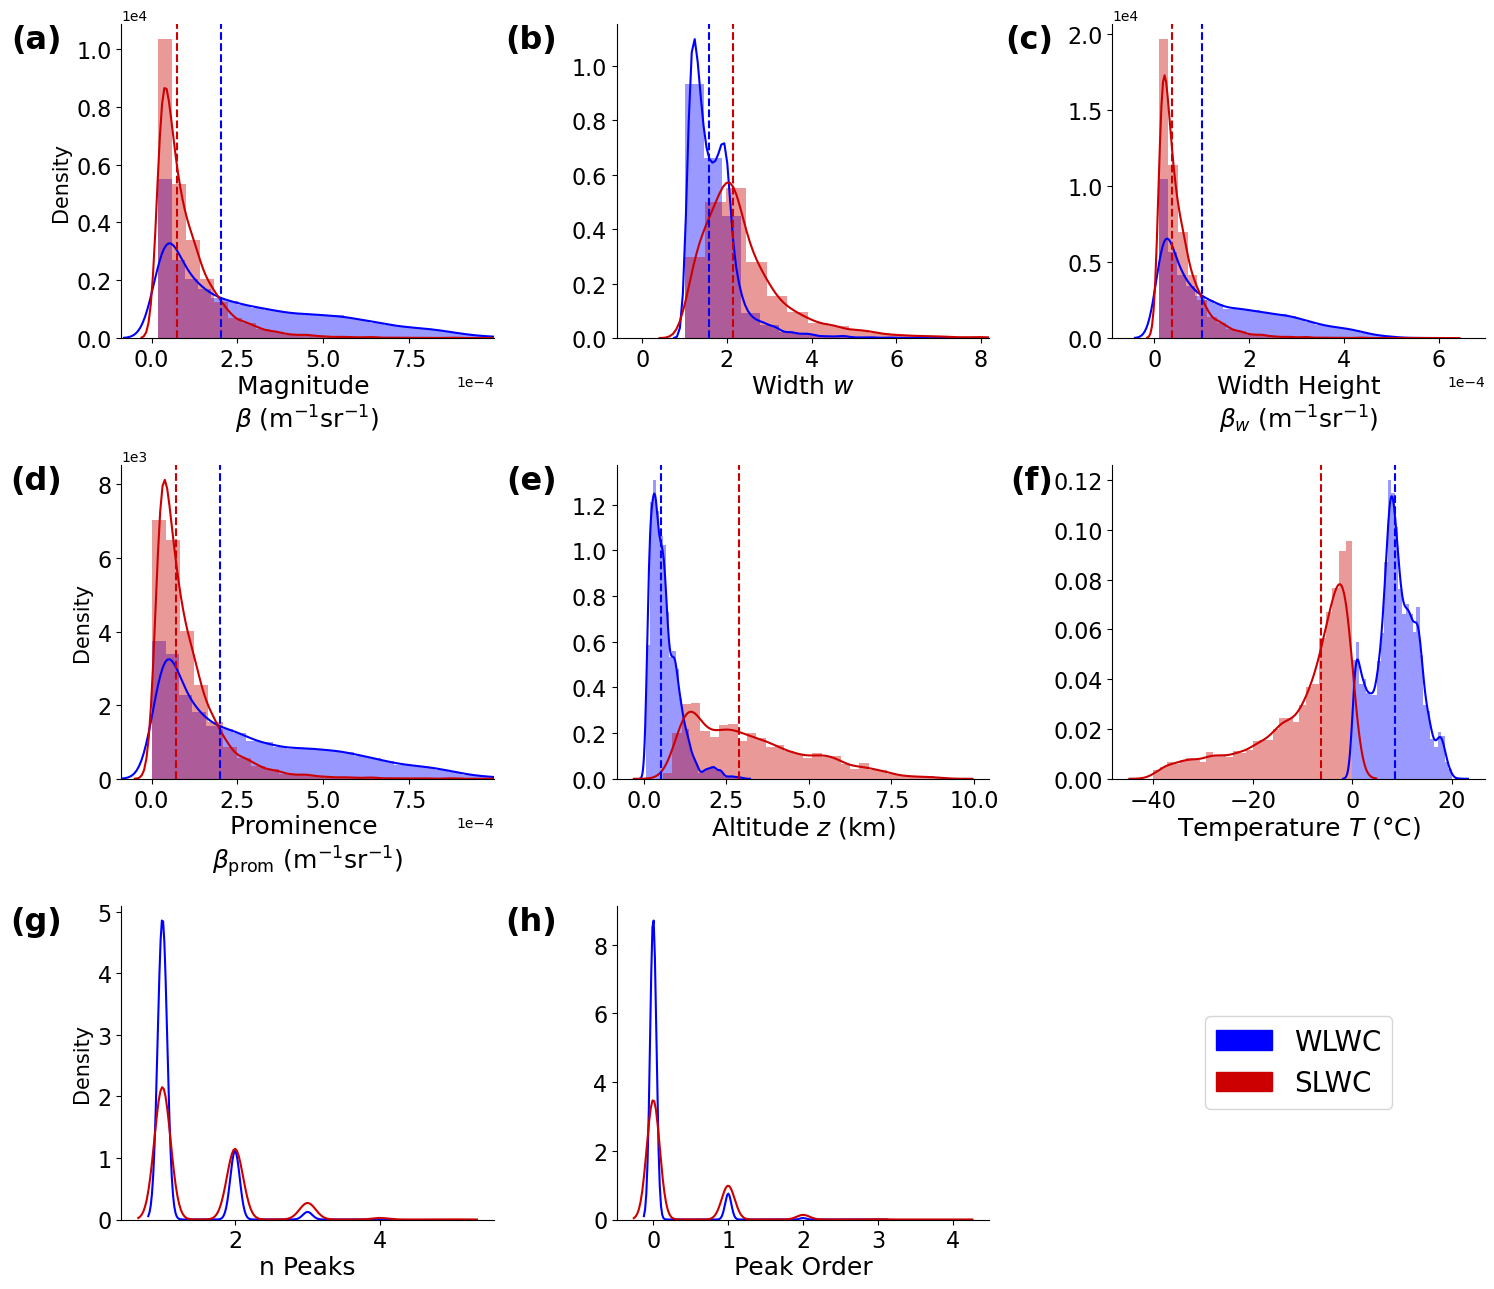

In [19]:
fig, axes = plt.subplots(3,3, figsize=(15,13))

var_list = ['peak_magnitude', 'peak_width', 'peak_width_height',
        'peak_prominence', 'peak_alt', 'peak_temp', 'num_peaks','peak_order',]

units_list = ['Magnitude \n$\\beta$ (m$^{-1}$sr$^{-1}$)', 'Width $w$', ' Width Height \n$\\beta_w$ (m$^{-1}$sr$^{-1}$)',
        'Prominence \n$\\beta_{\\text{prom}}$ (m$^{-1}$sr$^{-1}$)', 'Altitude $z$ (km)', 'Temperature $T$ ($\\degree$C)', 'n Peaks','Peak Order',]

letters='abcdefgh'

for i,var in enumerate(var_list):
    # print(var)
    
    ax = axes.flatten()[i]
    
    ax.tick_params(axis='both',which='major',labelsize=16)
    ax.tick_params(axis='both',which='minor',labelsize=16)
    
    ax.ticklabel_format(axis='x',style='sci',scilimits=(0,5))
    
    if var in ['num_peaks','peak_order']:
        sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30,hist=False)
        sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30,hist=False)

        # sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30,hist=False)
        # sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30,hist=False)
        # sns.distplot(mpc_peaks[var],label='MPC',ax=ax, color=c1,bins=30,hist=False)
        # sns.distplot(ic_peaks[var],label='IC',ax=ax, color=c4,bins=30,hist=False)    
        # sns.distplot(u_peaks[var],label='Un',ax=ax, color=c5,bins=30,hist=False)    
    else:
        sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30)
        sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30)

        # sns.distplot(wlcw_peaks[var],label='WLWC',ax=ax, color=c3,bins=30)
        # sns.distplot(slwc_peaks[var],label='SLWC',ax=ax, color=c2,bins=30)
        # sns.distplot(mpc_peaks[var],label='MPC',ax=ax, color=c1,bins=30)
        # sns.distplot(ic_peaks[var],label='IC',ax=ax, color=c4,bins=30)    
        # sns.distplot(u_peaks[var],label='Un',ax=ax, color=c5,bins=30)    
    
        ax.axvline(np.nanmedian(wlcw_peaks[var]),c=c3,linestyle='--', label='WLWC Median')
        ax.axvline(np.nanmedian(slwc_peaks[var]),c=c2,linestyle='--', label='SLWC Median')

        # ax.axvline(np.nanmedian(wlcw_peaks[var]),c=c3,linestyle='--', label='WLWC Median')
        # ax.axvline(np.nanmedian(slwc_peaks[var]),c=c2,linestyle='--', label='SLWC Median')
        # ax.axvline(np.nanmedian(mpc_peaks[var]),c=c1,linestyle='--', label='MPC Median')
        # ax.axvline(np.nanmedian(ic_peaks[var]),c=c4,linestyle='--', label='IC Median')
        # ax.axvline(np.nanmedian(u_peaks[var]),c=c5,linestyle='--', label='Undetermined Median')
    
    unit = units_list[i]
    ax.set_xlabel(unit,fontsize=18,labelpad=2)
    # ax.set_title(var,fontsize=20)
    
    ax.ticklabel_format(axis='both',style='sci',scilimits=(-2,2))
    
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
        
    
    if i in [0,3,6]:
        ax.set_ylabel('Density', fontsize=15)
    else:
        ax.set_ylabel(' ')
            
    ax.text(-0.16,1,'({})'.format(letters[i]),fontsize=23,transform=ax.transAxes,ha='right',va='top',weight='semibold')
        

# print(axes[0,2].get_xlim())
axes[0,0].set_xlim(-8.789452652380182e-05, 0.0009970278532549434) #height
# axes[0,0].set_xlim(-8.789452652380182e-02, 0.9970278532549434) #height

axes[0,2].set_xlim(-8.789452652380182e-05, 0.0006970278532549434) #width height
axes[1,0].set_xlim(-8.789452652380182e-05, 0.0009970278532549434) #prom

axes[0,1].set_xlim(-0.6,8.2) # width
# axes[1,1].set_xlim(-1,9) # altitude

axes[2,2].axis('off')

colour_labels = ['WLWC','SLWC']
patch_colors = [ c3,c2]
patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

# colour_labels = ['WLWC','SLWC','MPC', 'IC', 'Undetermined']
# patch_colors = [ c3,c2,c1, c4, c5]
# patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

# linestyle_labels = ['WLWC Median', 'SLWC Median','MPC Median','IC Median', 'Undetermined Median']
# patches_lines = [mlines.Line2D([],[],color=patch_colors[i],linestyle='dashed', label=linestyle_labels[i]) for i in range(5)] 
# patches = [patches_colours[0]] + [patches_lines[0]] + [patches_colours[1]] + [patches_lines[1]]  + [patches_colours[2]] + [patches_lines[2]] + [patches_colours[3]] + [patches_lines[3]] + [patches_colours[4]] + [patches_lines[4]]
patches = patches_colours
axes[2,2].legend(handles=patches, loc='center', fontsize=20)#,borderaxespad=0. )
    
# plt.text(0.2,0.65,'# Liquid peaks   =    '+ str(len(LCC_peaks)),transform=axes[2,2].transAxes,fontsize=17)
# plt.text(0.2,0.55,'# Ice peaks = '+ str(len(ICC_peaks)),transform=axes[2,2].transAxes,fontsize=17)
plt.tight_layout()

output_fpath = output_dir+'feature_dist_wlwc_slwc_med.png'
plt.savefig(output_fpath, dpi=150)
# plt.show()

### Fig 1

In [109]:
primary_peaks = peaks_df.query('peak_order == 0')
secondary_peaks = peaks_df.query('peak_order > 0')

In [133]:
secondary_peaks

,date,peak_time_idx,peak_alt_idx,peak_magnitude,peak_width,peak_width_height,peak_prominence,peak_alt,num_peaks,peak_order,peak_temp,wlwc_target,slwc_target,slcc_target,mpc_target,ic_target,undet_target,unan_target
43,20210515,252,129,0.000020,8.057845,0.000010,1.964156e-05,6.475,2,1,-36.199362,0,0,0,0,1,0,0
54,20210515,272,129,0.000028,1.538557,0.000028,1.793037e-07,6.475,2,1,-36.401232,0,0,0,0,1,0,0
56,20210515,273,128,0.000032,2.433759,0.000032,5.040295e-07,6.425,2,1,-35.835308,0,0,0,0,1,0,0
59,20210515,275,126,0.000020,4.560963,0.000019,2.596833e-06,6.325,2,1,-34.985875,0,0,0,0,1,0,0
71,20210515,286,105,0.000034,3.354361,0.000032,3.209134e-06,5.275,2,1,-26.170291,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34447,20220120,147,67,0.000028,1.760160,0.000014,2.700588e-05,3.375,3,2,-10.736282,0,1,1,0,0,0,0
34449,20220120,148,60,0.000070,2.306723,0.000035,7.014005e-05,3.025,2,1,-8.109334,0,1,1,0,0,0,0
34493,20220120,222,83,0.000169,2.350006,0.000084,1.694103e-04,4.175,2,1,-12.374001,0,1,1,0,0,0,0
34515,20220120,263,67,0.000121,1.769463,0.000060,1.217493e-04,3.375,2,1,-6.141288,0,1,1,0,0,0,0


In [111]:
q2_prim = np.median(primary_peaks['peak_magnitude'])
q2_sec = np.median(secondary_peaks['peak_magnitude'])

In [115]:
import scipy

In [116]:
q2_prim_mad = scipy.stats.median_abs_deviation(primary_peaks['peak_magnitude'])
q2_sec_mad = scipy.stats.median_abs_deviation(secondary_peaks['peak_magnitude'])

diff = q2_prim-q2_sec

print('Primary peaks: Median = {:.3e} with {:.3e} MAD'.format(q2_prim,q2_prim_mad))
print('Secondary peaks: Median = {:.3e} with {:.3e} MAD'.format(q2_sec,q2_sec_mad))
print('Difference = {:.3e}'.format(diff))

Primary peaks: Median = 1.112e-04 with 8.197e-05 MAD
Secondary peaks: Median = 4.340e-05 with 1.838e-05 MAD
Difference = 6.785e-05


In [130]:
1.1e-4-4.3e-5


6.7e-05

/tmp/ipykernel_4939/2528272428.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  c5 = cm.get_cmap('RdYlBu_r', 10)(8)
/tmp/ipykernel_4939/2528272428.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  c6 = cm.get_cmap('RdYlBu_r', 10)(2)
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/lukeew/anaconda3/envs/01_SLW_xgb/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na op

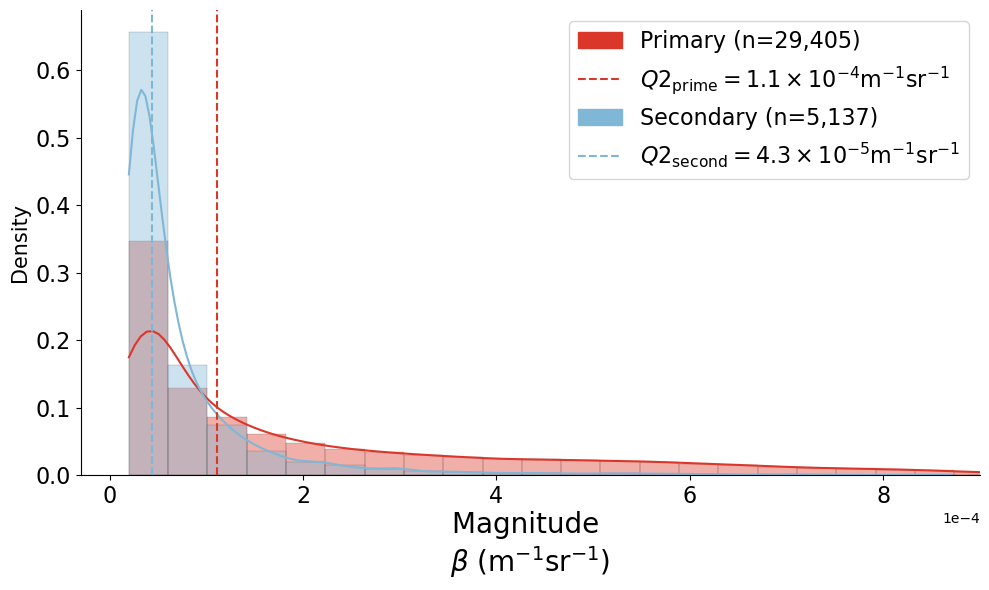

In [128]:
from matplotlib import cm
c5 = cm.get_cmap('RdYlBu_r', 10)(8)
c6 = cm.get_cmap('RdYlBu_r', 10)(2)

unit='Magnitude \n$\\beta$ (m$^{-1}$sr$^{-1}$)'

fig, (ax) = plt.subplots(1,1,figsize=(10,6))

ax.tick_params(axis='both',which='major',labelsize=16)
ax.tick_params(axis='both',which='minor',labelsize=16)

ax.ticklabel_format(axis='x',style='sci',scilimits=(0,5))

# kde_kws={'clip':(0,5e-4)}
kde_kws={'cut':0}
# kde_kws={}

bin_min = np.min(primary_peaks['peak_magnitude'])
bin_max = np.max(primary_peaks['peak_magnitude'])
# hist_kws = {'binrange':(bin_min,bin_max)}
hist_kws = {}
line_kws = dict(linewidth=0)

# sns.distplot(primary_peaks['peak_backscatter'],label='Primary',ax=ax,bins=30,color=c5,kde=True,hist=True,kde_kws=kde_kws, hist_kws=hist_kws)
# sns.distplot(secondary_peaks['peak_backscatter'],label='Secondary',ax=ax,bins=30,color=c6,kde=True,hist=True,kde_kws=kde_kws, hist_kws=hist_kws)    

sns.histplot(primary_peaks['peak_magnitude'],label='Primary',ax=ax,bins=30,
            color=c5,kde=True,alpha=0.4, binrange=(bin_min,bin_max), 
            stat='proportion', linewidth=0.1, kde_kws=dict(cut=0))
sns.histplot(secondary_peaks['peak_magnitude'],label='Secondary',ax=ax,bins=30,
            color=c6,kde=True,alpha=0.4, binrange=(bin_min,bin_max), 
            stat='proportion', linewidth=0.1, kde_kws=dict(cut=0))   

ax.axvline(q2_prim,c=c5, label='SLCC Median',linestyle='--')
ax.axvline(q2_sec,c=c6, label='WLCC Median',linestyle='--')

# ax.axvline(q2_prim-q2_prim_mad,c=c2,linestyle='--')
# ax.axvline(q2_sec-q2_sec_mad,c=c4,linestyle='--')

# ax.axvline(q2_prim+q2_prim_mad,c=c2,linestyle='--')
# ax.axvline(q2_sec+q2_sec_mad,c=c4,linestyle='--')

# unit = units_list[i]
ax.set_xlabel(unit,fontsize=20,labelpad=2)
# ax.set_title(var,fontsize=20)

ax.ticklabel_format(axis='both',style='sci',scilimits=(-2,2))

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
    
ax.set_ylabel('Density', fontsize=15)

n_prim = len(primary_peaks['peak_magnitude'])
n_sec = len(secondary_peaks['peak_magnitude'])

# colour_labels = ['Primary (n={})'.format(n_prim),'Secondary (n={})'.format(n_sec)]
colour_labels = ['Primary (n=29,405)','Secondary (n=5,137)']

patch_colors = [ c5,c6]
patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

# linestyle_labels = ['$Q2_{\mathrm{prime}}$ = %.1e'%(q2_prim), '$Q2_{\mathrm{second}}$ = %.1e'%(q2_sec)]
linestyle_labels = [r'$Q2_{\mathrm{prime}}=1.1\times10^{-4}\mathrm{m}^{-1}\mathrm{sr}^{-1}$',
                    r'$Q2_{\mathrm{second}}=4.3\times10^{-5}\mathrm{m}^{-1}\mathrm{sr}^{-1}$']

patches_lines = [mlines.Line2D([],[],color=patch_colors[i],linestyle='--', label=linestyle_labels[i]) for i in range(2)] 
patches = [patches_colours[0]] + [patches_lines[0]] + [patches_colours[1]] + [patches_lines[1]]
# patches = patches_colours + patches_lines
ax.legend(handles=patches, loc='upper right', fontsize=16)#,borderaxespad=0. )  
# ax.text(-0.13,1,'{}'.format(letters[i]),fontsize=25,transform=ax.transAxes,ha='right',va='top',weight='semibold')
        
ax.set_xlim(-3e-5,9e-4)

plt.tight_layout()

output_fpath = output_dir+'prim_sec_pks.png'
plt.savefig(output_fpath,dpi=150)


In [ ]:
## Altitude by width scatter plot

# q2_SLCC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))
# q2_WLWC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))
# q2_SLWC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))
# q2_IC_all = np.empty(len(np.unique(peaks_df['peak_alt'])))


# for idx, alt in enumerate(np.unique(peaks_df['peak_alt'])):
#     peaks_df_alt = peaks_df.query('peak_alt=={}'.format(alt))
    
#     SLCC_peaks = peaks_df_alt.query('slcc_target == 1')
#     WLWC_peaks = peaks_df_alt.query('wlwc_target == 1')
#     SLWC_peaks = peaks_df_alt.query('slwc_target == 1')
#     IC_peaks = peaks_df_alt.query('ic_target == 1')

#     var = 'peak_width'
#     q2_SLCC = np.nanmedian(SLCC_peaks[var])
#     q2_WLWC = np.nanmedian(WLWC_peaks[var])
#     q2_SLWC = np.nanmedian(SLWC_peaks[var])
#     q2_ICLCC = np.nanmedian(IC_peaks[var])
    
#     q2_SLCC_all[idx]= q2_SLCC
#     q2_WLWC_all[idx]= q2_WLWC
#     q2_SLWC_all[idx]= q2_SLWC
#     q2_IC_all[idx]= q2_ICLCC

# plt.scatter(q2_IC_all,np.unique(peaks_df['peak_alt']),color=c1)
# plt.scatter(q2_WLWC_all,np.unique(peaks_df['peak_alt']),color=c2)